#02 Neural Nwtwork classification with PyTorch

Classification is a probelm of predicting whether something is one thing or another (there can be multiple things as the options).

Book version of this notebook-https://github.com/mrdbourke/pytorch-deep-learning/blob/main/02_pytorch_classification.ipynb

## 1.Make classification data and get it ready

In [116]:
import sklearn

In [117]:
from sklearn.datasets import make_circles

#Make 1000 samples
n_samples=1000

#Create circles
X,y=make_circles(
    n_samples,    # 產生 1000 個點
    noise=0.03,        # 加一點隨機雜訊
    random_state=42    # 固定亂數結果像是manual_seed，方便重現
)

In [118]:
len(X),len(y)

(1000, 1000)

In [119]:
print(f"First 5 samples of X:{X[:5]}")
print(f"First 5 samples of y:{y[:5]}")

First 5 samples of X:[[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]
First 5 samples of y:[1 1 1 1 0]


In [120]:
#Make DataFrame of circle data
import pandas as pd


circles = pd.DataFrame({
    "X1": X[:, 0],  # 所有 row，第 0 欄
    "X2": X[:, 1],   # 所有 row，第 1 欄
    "label": y      # 每筆資料對應的分類標籤（0 或 1）
})

circles.head(10)

,X1,X2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


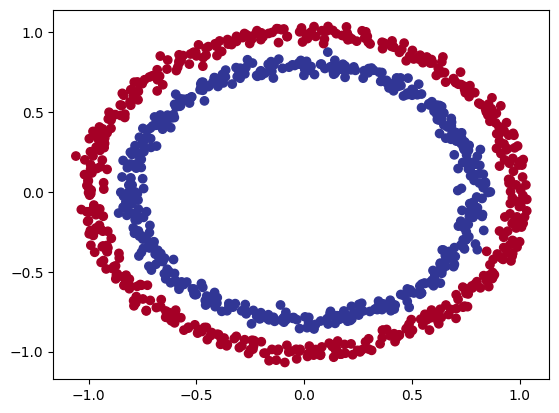

In [121]:
#Visualize,visualize,visualize
import matplotlib.pyplot as plt
plt.scatter(x=X[:,0], # X 軸：所有資料的第 1 個 feature
            y=X[:,1], # Y 軸：所有資料的第 2 個 feature
            c=y,      # 根據 label（0 / 1）決定點的顏色
            cmap=plt.cm.RdYlBu)# 指定顏色配置：紅 → 黃 → 藍

**Note**: The data we’re working with is often referred to as a toy dataset, a dataset that is small enough to experiment with but still sizeable enough to practice the fundamentals.

### 1.1 Check input and output shapes

In [122]:
X.shape, y.shape

((1000, 2), (1000,))

In [123]:
X

array([[ 0.75424625,  0.23148074],
       [-0.75615888,  0.15325888],
       [-0.81539193,  0.17328203],
       ...,
       [-0.13690036, -0.81001183],
       [ 0.67036156, -0.76750154],
       [ 0.28105665,  0.96382443]])

In [124]:
#View the first example of features and labels
X_sample=X[0]
y_sample=y[0]

print(f"Values for one sample of X:{X_sample} and the same for y:{y_sample}")
print(f"Shapes for one sample of X:{X_sample.shape} and the same for y:{y_sample.shape}")



Values for one sample of X:[0.75424625 0.23148074] and the same for y:1
Shapes for one sample of X:(2,) and the same for y:()


### 1.2 Turn data into tensors and create train and test splits

In [125]:
#Turn data into tensors
import torch
torch.__version__

'2.11.0+cu130'

In [126]:
type(X),X.dtype

(numpy.ndarray, dtype('float64'))

In [127]:
#Turn  NumPy array  into PyTorch Tensor
#X.numpy():tensor to numpy
X=torch.from_numpy(X).type(torch.float)
y=torch.from_numpy(y).type(torch.float)

X[:5],y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [128]:
type(X),X.dtype,y.dtype

(torch.Tensor, torch.float32, torch.float32)

In [129]:
#Split data into trainig and test sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,#0.2 means 20 of data will be test & 80 will be train
                                                    random_state=42)



In [130]:
len(X_train),len(X_test),len(y_train),len(y_test)

(800, 200, 800, 200)

In [131]:
n_samples

1000

## 2.Building a model

Let's build a model to classify our blue and red dots.

To do so,we want to:
1. Setup device agonistic code so our code will run on an accelerator(GPU) if there is one
2. Construct a model (by subclassing `nn.Module`)
3. Define a loss function and optimizer
4. Create a training and test loop


In [132]:
#import PyTorch and nn
import torch
from torch import nn

#Make device agnostic code
device="cuda" if torch.cuda.is_available() else "cpu"

print(device)

cuda


In [133]:
X_train

tensor([[ 0.6579, -0.4651],
        [ 0.6319, -0.7347],
        [-1.0086, -0.1240],
        ...,
        [ 0.0157, -1.0300],
        [ 1.0110,  0.1680],
        [ 0.5578, -0.5709]])

Now we've setup device agnostic code, let's create a model that:

1. Subclasses `nn.Module` (almost all models in PyTorch subclass `nn.Module`)
2. Create 2 `nn.Linear()` layers that are capable of handling the shapes of our data
3. Defines a `forward()` method that outlines the forward pass (or forward computation) of the model
4. Instantiate an instance of our model class and send it to the target `device`

In [134]:
X_train.shape

torch.Size([800, 2])

In [135]:
y_train[:5]

tensor([1., 0., 0., 0., 1.])

In [136]:
#1. Construct a model that subclasses nn.Module
class CircleModelV0(nn.Module):
  def __init__(self):
    super().__init__()
    #2. Create 2 nn.Linear layers capable of handling the shapes of our data
    self.layer_1=nn.Linear(in_features=2,out_features=5)# takes in 2 features and upscales to 5 features
    self.layer_2=nn.Linear(in_features=5,out_features=1)#takes in 5 features from previous layer and outputs a single feature (same shape as y)

  #3.Define a forward() method that outlines the forward pass
  def forward(self,x):
    return self.layer_2(self.layer_1(x))# x->layer_1 ->layer_2 ->output

# 4. Instantiate an instance of our model class and send it to the target device
model_0=CircleModelV0().to(device)
model_0


CircleModelV0(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)

In [137]:
model_0.state_dict() # View the model's learnable parameters (weights and biases)

OrderedDict([('layer_1.weight',
              tensor([[ 0.5406,  0.5869],
                      [-0.1657,  0.6496],
                      [-0.1549,  0.1427],
                      [-0.3443,  0.4153],
                      [ 0.6233, -0.5188]], device='cuda:0')),
             ('layer_1.bias',
              tensor([0.6146, 0.1323, 0.5224, 0.0958, 0.3410], device='cuda:0')),
             ('layer_2.weight',
              tensor([[-0.0631,  0.3448,  0.0661, -0.2088,  0.1140]], device='cuda:0')),
             ('layer_2.bias', tensor([-0.2060], device='cuda:0'))])

In [138]:
device

'cuda'

In [139]:
next(model_0.parameters()).device  # Check which device the model is on

device(type='cuda', index=0)

In [140]:
#Let's replicate the model above using nn.Sequential()
#(nn.Suqential)它的主要功能就是：把多個神經網路層按照順序串起來，資料會自動一層一層往下傳
model_0=nn.Sequential(
    nn.Linear(in_features=2,out_features=5),
    nn.Linear(in_features=5,out_features=1)
).to(device)

model_0

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

In [141]:
## state_dict：儲存模型中所有可學習參數（weights 和 biases）的字典
model_0.state_dict()

OrderedDict([('0.weight',
              tensor([[-0.0829, -0.2872],
                      [ 0.4691, -0.5582],
                      [-0.3260, -0.1997],
                      [-0.4252,  0.0667],
                      [-0.6984,  0.6386]], device='cuda:0')),
             ('0.bias',
              tensor([-0.6007,  0.5459,  0.1177, -0.2296,  0.4370], device='cuda:0')),
             ('1.weight',
              tensor([[ 0.0697,  0.3613,  0.0489, -0.1410,  0.1202]], device='cuda:0')),
             ('1.bias', tensor([-0.1213], device='cuda:0'))])

In [142]:
#Make predictions
#推論模式：不追蹤梯度，只做預測，節省記憶體並加快運算
with torch.inference_mode():
  untrained_preds=model_0(X_test.to(device))

print(f"Length of predictions:{len(untrained_preds)}")
print(f"Length of  samples:{len(X_test)},Shape: {X_test.shape}")
print(f"\nFirst 10 Predictions:\n{untrained_preds[:10]}")
print(f"\nFirst 10 labels:\n{y_test[:10]}")

Length of predictions:200
Length of  samples:200,Shape: torch.Size([200, 2])

First 10 Predictions:
tensor([[-0.0338],
        [-0.0309],
        [ 0.0894],
        [-0.0692],
        [ 0.2967],
        [ 0.2968],
        [ 0.1405],
        [ 0.2178],
        [ 0.0805],
        [-0.0284]], device='cuda:0')

First 10 labels:
tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


In [143]:
y_test[:10],X_test[:10]

(tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.]),
 tensor([[-0.3752,  0.6827],
         [ 0.0154,  0.9600],
         [-0.7028, -0.3147],
         [-0.2853,  0.9664],
         [ 0.4024, -0.7438],
         [ 0.6323, -0.5711],
         [ 0.8561,  0.5499],
         [ 1.0034,  0.1903],
         [-0.7489, -0.2951],
         [ 0.0538,  0.9739]]))

### 2.1 Setup loss function and optimizer
Which loss function or optimizer should you use?

Again... this is problem speicific.

For example for regression you might want MAE or MSE (mean absolute error or mean squared error)

For classification you might eant binary cross entropy or categorical cross entropy(cross entropy)

As a reminder,the loss function measures how *wrong* your modele predictions are.

Add for optimizers ,two of the most common and useful are SGD and Adam,hover PyTorch has many built-in options.

**SGD** = Stochastic Gradient Descent(隨機梯度下降)

**Adam** 也是更新參數的方法:Adam 會根據過去的 gradient 動態調整每個參數的更新幅度，通常比單純 SGD 更有彈性。

Softmax = 把模型輸出的分數轉成「機率分布」

* For some common choices of loss functions and optimizers
* For the loss function we're going to use `torch.nn.BECWithLogitsLoss()`,for more on what binary cross entropy (BCE) is ,check out this article - https://towardsdatascience.com/logit-of-logistic-regression-understanding-the-fundamentals-f384152a33d1/

* For a definition on what a logit is in deep learning - https://stackoverflow.com/questions/41455101/what-is-the-meaning-of-the-word-logits-in-tensorflow

* For different optimizer see `torch.optim`


In [144]:
#Setup the loss function
#loss_fn=nn.BCELoss()# BCELoss=requires inputs to have gone through the sigmoid activation function prior to input to BCELoss

nn.Sequential(
    nn.Sigmoid(),
    nn.BCELoss()
)

loss_fn=nn.BCEWithLogitsLoss()#BCEWitchLogitsLoss=sigmoid activation function built-in
#BCEWithLogitsLoss = Sigmoid + Binary Cross Entropy Loss
#主要用在二元分類(Binary Classification)

# BCELoss
# → 沒有內建 Sigmoid

# BCEWithLogitsLoss
# → 有內建 Sigmoid

optimizer=torch.optim.SGD(params=model_0.parameters(),
                          lr=0.1)



In [145]:
#Calculate  accuracy -out of 100 examples ,what percentage does our model get right
def accuracy_fn(y_true,y_pred):
  correct=torch.eq(y_true,y_pred).sum().item()
  acc=(correct/len(y_pred))*100
  return acc
#10:12:07

## 3.Train model
To train our model,we're going to need to build a training loop:

1. Forward pass
2. Calculate the loss
3. Optimizer zero grad
4. Loss backward(backpropagation)
5. Optimizer step(gradient,descent)

### 3.1 Going from raw logits->prediction probabilites->prediction labels

Our model outputs are going to be raw **logits**.

We can convert these **logits** into **prediction probabilities** by passing them to some kind of **activation function**  
(e.g. `sigmoid` for binary classification and `softmax` for multiclass classification).

Then we can convert our model's **prediction probabilities** to **prediction labels** by either **rounding** them or taking the `argmax()`.

In [146]:
# View the first 5 outputs of the forward pass on the test data
model_0.eval()
with torch.inference_mode():
  y_logits=model_0(X_test.to(device))[:5]
y_logits

tensor([[-0.0338],
        [-0.0309],
        [ 0.0894],
        [-0.0692],
        [ 0.2967]], device='cuda:0')

In [147]:
y_test[:5]


tensor([1., 0., 1., 0., 1.])

In [148]:
#use the sigmoid activation function on our model logits
#把模型輸出的 logits 轉換成 0～1 之間的機率
y_pred_probs=torch.sigmoid(y_logits)
y_pred_probs

tensor([[0.4916],
        [0.4923],
        [0.5223],
        [0.4827],
        [0.5736]], device='cuda:0')

For our prediction probability values,we need to perfrom a range-style rounding on them:
* `y_pred_probs>=0.5,y=1(class1)`
* `y_pred_probs<0.5,y=0(class0)`

In [149]:
#find the predicted labels
y_preds=torch.round(y_pred_probs)

#in full(logits->pred probs->pred labels)
y_pred_labels=torch.round(torch.sigmoid(model_0(X_test.to(device))[:5]))

 #check for equality
print(torch.eq(y_preds.squeeze(),y_pred_labels.squeeze ()))

#Get rid of extra dimension
y_preds.squeeze()


tensor([True, True, True, True, True], device='cuda:0')


tensor([0., 0., 1., 0., 1.], device='cuda:0')

In [150]:
y_test[:5]

tensor([1., 0., 1., 0., 1.])

### 3.2 Building a training and testing loop


In [151]:
"cuda" if torch.cuda.is_available() else "cpu"

'cuda'

In [152]:
!nvidia-smi

Thu Oct 22 13:05:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             35W /   70W |     161MiB /  15360MiB |      1%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [153]:
from numpy import test
torch.manual_seed(42)
torch.cuda.manual_seed(42)

#set the number of epochs
epochs=100

#put data to target device
X_train,y_train=X_train.to(device),y_train.to(device)
X_test,y_test=X_test.to(device),y_test.to(device)

#build training and evaluation loop
for epoch in range(epochs):
  ###Training(default)
  model_0.train()

  #1.Forward pass
  y_logits=model_0(X_train).squeeze()
  y_pred=torch.round(torch.sigmoid(y_logits))#turn logits -pred probs->pred labels

  #2. calculate the loss
  #loss=loss_fn(torch.sigmoid(y_logits),#nn.BCELoss expects predictions as input
  #             y_train)
  loss=loss_fn(y_logits,# nn.BCEWithLogitsLoss expects raw logits as input
               y_train)
  acc=accuracy_fn(y_true=y_train,
                  y_pred=y_pred)
  #3. optimizer zero grad
  optimizer.zero_grad()

  #4.loss backward(backpropagation)
  loss.backward()

  #5.optimizer step(gradient descent)
  optimizer.step()

  ####Testing
  model_0.eval()
  with torch.inference_mode():
    #1. forward pass
    test_logits=model_0(X_test).squeeze()
    test_pred=torch.round(torch.sigmoid(test_logits))

    #2. calculate test loss/accuracy
    test_loss=loss_fn(test_logits,y_test)
    test_acc=accuracy_fn(y_true=y_test,
                         y_pred=test_pred)

    #Print out what's happenin'
    if epoch % 10==0:
      print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")


Epoch: 0 | Loss: 0.69796, Acc: 51.88% | Test Loss: 0.69440, Test Acc: 58.00%
Epoch: 10 | Loss: 0.69590, Acc: 51.25% | Test Loss: 0.69305, Test Acc: 53.00%
Epoch: 20 | Loss: 0.69490, Acc: 51.62% | Test Loss: 0.69254, Test Acc: 49.50%
Epoch: 30 | Loss: 0.69435, Acc: 51.12% | Test Loss: 0.69236, Test Acc: 49.50%
Epoch: 40 | Loss: 0.69401, Acc: 50.88% | Test Loss: 0.69232, Test Acc: 51.00%
Epoch: 50 | Loss: 0.69378, Acc: 50.25% | Test Loss: 0.69234, Test Acc: 50.00%
Epoch: 60 | Loss: 0.69362, Acc: 50.00% | Test Loss: 0.69239, Test Acc: 51.50%
Epoch: 70 | Loss: 0.69351, Acc: 50.25% | Test Loss: 0.69246, Test Acc: 51.00%
Epoch: 80 | Loss: 0.69342, Acc: 49.88% | Test Loss: 0.69254, Test Acc: 50.00%
Epoch: 90 | Loss: 0.69336, Acc: 49.88% | Test Loss: 0.69262, Test Acc: 53.00%


In [154]:
loss_fn

BCEWithLogitsLoss()


## 4.Make predictions and evaluate the model

From the metrics it looks like our model isn't learning anything...

So to inspect it let's make some predictions and make them visual!

In other words, **"Visualize, visualize, visualize!"**

To do so ,we're going to import a function called `plot_decision_boundary()`
-https://github.com/mrdbourke/pytorch-deep-learning/blob/main/helper_functions.py

In [155]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo
if Path("helper_functions.py").is_file():
    print("helper_functions.py already exists, skipping download")
else:
    print("Downloading helper_functions.py")

    request = requests.get(
        "https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py"
    )

    with open("helper_functions.py", "wb") as file:
        file.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary

helper_functions.py already exists, skipping download


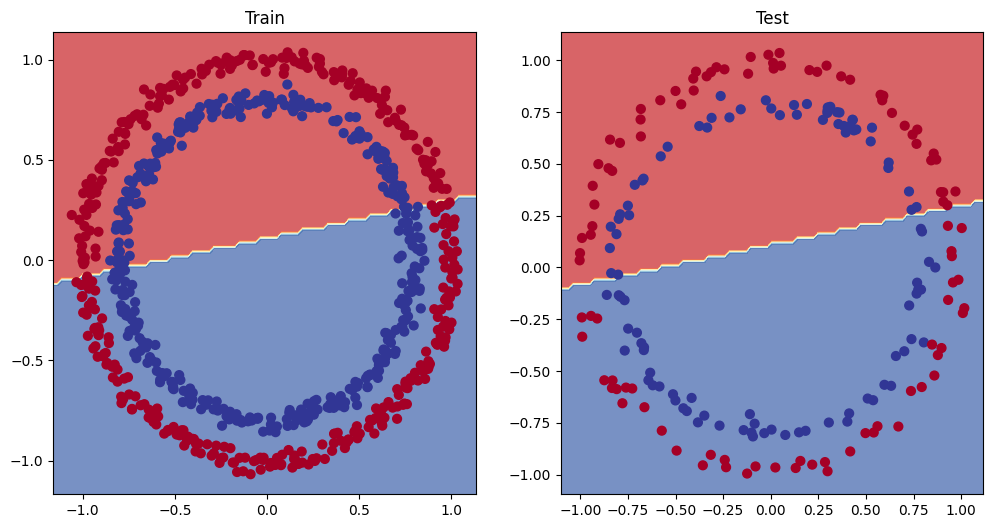

In [156]:
#plot decision boundary of the model
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_0,X_train,y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_0,X_test,y_test)



## 5.Improving a model (from a model perspective)

* Add more layers -give the modelmore chances to learn about patterns int the data
* Add more hidden units -go from 5 hidden units to 10 hidden units
* Fit for longer
*Changing the activation functions
* Change the learning rate
* Change the loss function

These optnios are all from a model's perspective becuase they deal directly with the model, rather than the data.

And because these options are all values we (as machine lerning engineers and data scientists) can change, they are referred as **hyperparameters**.

Let's try and improce our model by :    
* Adding more hidden units :5->10
* Increase tne number of layers: 2-> 3
* Increase the number of epochs: 100->1000

In [157]:
X_train[:5],y_train[:5]

(tensor([[ 0.6579, -0.4651],
         [ 0.6319, -0.7347],
         [-1.0086, -0.1240],
         [-0.9666, -0.2256],
         [-0.1666,  0.7994]], device='cuda:0'),
 tensor([1., 0., 0., 0., 1.], device='cuda:0'))

In [158]:
class CircleModelV1(nn.Module):
  def __init__(self):
    super().__init__()
    #Adding more hidden units :5->10
    #Increase tne number of layers: 2-> 3
    self.layer_1=nn.Linear(in_features=2,out_features=10)
    self.layer_2=nn.Linear(in_features=10,out_features=10)
    self.layer_3=nn.Linear(in_features=10,out_features=1)

  def forward(self,x):
    # z=self.layer_1(x)
    # z=self.layer_2(z)
    # z=self.layer_3(z)

    #加速運算
    return self.layer_3(self.layer_2(self.layer_1(x)))# this way of writing operations leverages speed ups where possible behind the scene

model_1=CircleModelV1().to(device)
model_1


CircleModelV1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

In [159]:
device

'cuda'

In [160]:
next(model_1.parameters()).device

device(type='cuda', index=0)

In [161]:
#Create a loss function
loss_fn=nn.BCEWithLogitsLoss()

#Create an optimizer
#lr stand for learning rate*
# lr=0.1：每次更新的幅度由梯度乘上 0.1 決定。
# lr=0.001：更新幅度較小，通常比較穩定。
# lr=1.0：更新幅度較大，可能無法收斂。
optimizer=torch.optim.SGD(params=model_1.parameters(),lr=0.1)


In [162]:
# Write a training and evaluation loop for model_1
torch.manual_seed(42)
torch.cuda.manual_seed(42)

#Train for longer
epochs=1000

#Put data on the target device
X_train,y_train=X_train.to(device),y_train.to(device)
X_test,y_test=X_test.to(device),y_test.to(device)

for epoch in range(0,epochs):
  #default
  model_1.train()

  #1.forward pass
  y_logits=model_1(X_train).squeeze()
  y_pred=torch.round(torch.sigmoid(y_logits))

  #2.calculate loss

  loss=loss_fn(y_logits,y_train)
  acc=accuracy_fn(y_true=y_train,
                  y_pred=y_pred)

  #3. optimizer zero grad
  optimizer.zero_grad()

  #4.loss backward(backpropagation)
  loss.backward()

  #5.optimizer step(gradient descent)
  optimizer.step()

  model_1.eval()
  with torch.inference_mode():
    #1.Forward pass
    test_logits=model_1(X_test).squeeze()
    test_pred=torch.round(torch.sigmoid(test_logits))

    test_loss=loss_fn(test_logits,y_test)
    test_acc=accuracy_fn(y_true=y_test,
                         y_pred=test_pred)


  #Print out what's happenin'
  if epoch % 100==0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")



Epoch: 0 | Loss: 0.69396, Acc: 50.88% | Test Loss: 0.69261, Test Acc: 51.00%
Epoch: 100 | Loss: 0.69305, Acc: 50.38% | Test Loss: 0.69379, Test Acc: 48.00%
Epoch: 200 | Loss: 0.69299, Acc: 51.12% | Test Loss: 0.69437, Test Acc: 46.00%
Epoch: 300 | Loss: 0.69298, Acc: 51.62% | Test Loss: 0.69458, Test Acc: 45.00%
Epoch: 400 | Loss: 0.69298, Acc: 51.12% | Test Loss: 0.69465, Test Acc: 46.00%
Epoch: 500 | Loss: 0.69298, Acc: 51.00% | Test Loss: 0.69467, Test Acc: 46.00%
Epoch: 600 | Loss: 0.69298, Acc: 51.00% | Test Loss: 0.69468, Test Acc: 46.00%
Epoch: 700 | Loss: 0.69298, Acc: 51.00% | Test Loss: 0.69468, Test Acc: 46.00%
Epoch: 800 | Loss: 0.69298, Acc: 51.00% | Test Loss: 0.69468, Test Acc: 46.00%
Epoch: 900 | Loss: 0.69298, Acc: 51.00% | Test Loss: 0.69468, Test Acc: 46.00%


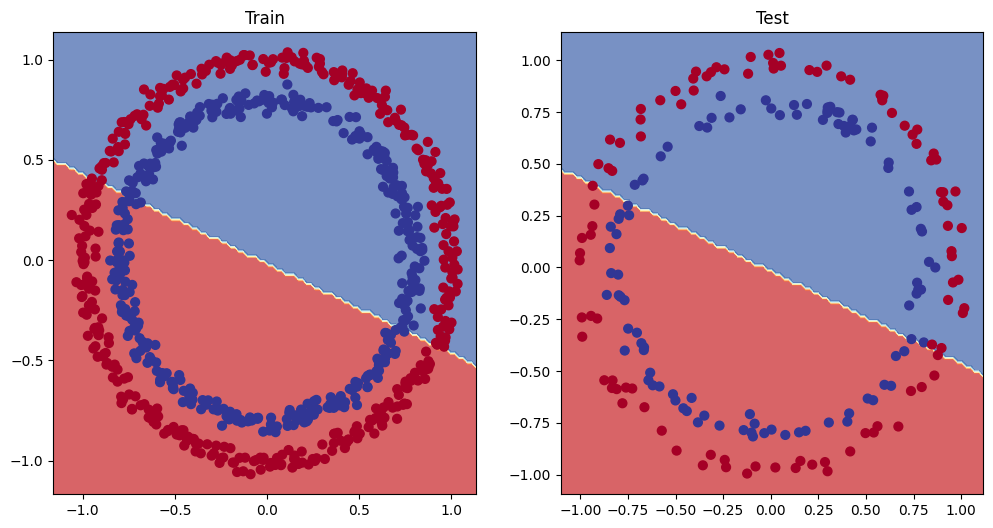

In [163]:
#Plot the decision boundary
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_1,X_train,y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_1,X_test,y_test)

### 5.1Preparing data to see if our model can fit a straight line

One way to troubleshoot to a larger problem is to test out a smaller problem.

In [164]:
# Create some data (smae a notebook 01)
weight=0.7
bias=0.3
start=0
end=1
step=0.01

#Create data
X_regression=torch.arange(start,end,step).unsqueeze(dim=1)
y_regression=weight*X_regression+bias #Linear regression formula (without epsilon)

#Check the data
print(len(X_regression))
print(X_regression[:5])
print(y_regression[:5])

100
tensor([[0.0000],
        [0.0100],
        [0.0200],
        [0.0300],
        [0.0400]])
tensor([[0.3000],
        [0.3070],
        [0.3140],
        [0.3210],
        [0.3280]])


In [165]:
#Create train andtest splits
train_split=int(0.8*len(X_regression))
X_train_regression,y_train_regression=X_regression[:train_split],y_regression[:train_split]
X_test_regression,y_test_regression=X_regression[train_split:],y_regression[train_split:]

#Check the data
print(len(X_train_regression),len(X_test_regression),len(y_train_regression),len(y_test_regression))

80 20 80 20


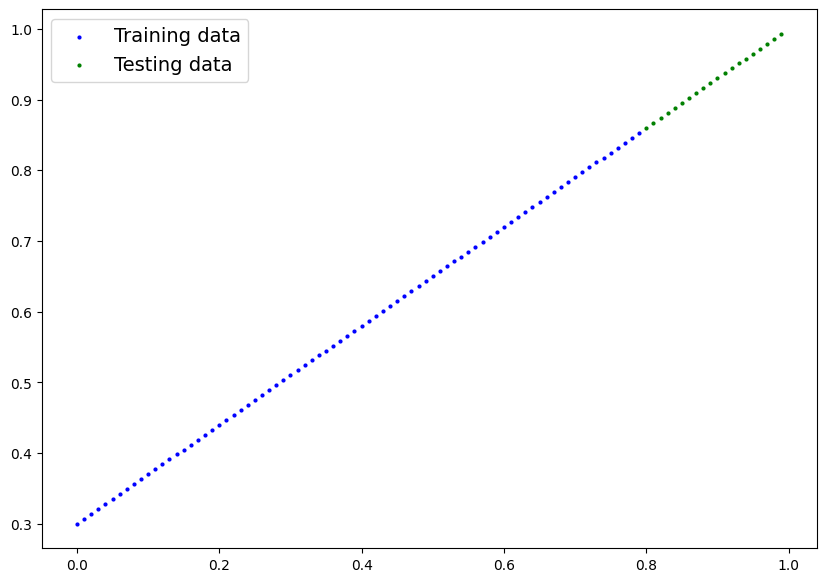

In [166]:
plot_predictions(train_data=X_train_regression,
                 train_labels=y_train_regression,
                 test_data=X_test_regression,
                 test_labels=y_test_regression);

In [167]:
X_train_regression[:10],y_train_regression[:10]

(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400],
         [0.0500],
         [0.0600],
         [0.0700],
         [0.0800],
         [0.0900]]),
 tensor([[0.3000],
         [0.3070],
         [0.3140],
         [0.3210],
         [0.3280],
         [0.3350],
         [0.3420],
         [0.3490],
         [0.3560],
         [0.3630]]))

### 5.2Adjusting `model_1` to fit a straight line

In [168]:
model_1

CircleModelV1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

In [169]:
#same architecture as model_1 (but using nn.Sequential())
# 最大的差別是：

# nn.Sequential()：自動依照順序執行每一層。
# self.layer_1：自己定義每一層，並在 forward() 中決定執行流程。

model_2=nn.Sequential(
    nn.Linear(in_features=1,out_features=10),
    nn.Linear(in_features=10,out_features=10),
    nn.Linear(in_features=10,out_features=1)
).to(device)

model_2
#11:39:00

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): Linear(in_features=10, out_features=10, bias=True)
  (2): Linear(in_features=10, out_features=1, bias=True)
)

In [170]:
#Loss and optimizer
#L1Loss 通常用於 Regression（迴歸），BCEWithLogitsLoss 用於 Binary Classification（二元分類）。
loss_fn=nn.L1Loss()#MAE loss wtih regression data
optimizer=torch.optim.SGD(params=model_2.parameters(),lr=0.01)


In [171]:
#Train the model

torch.manual_seed(42)
torch.cuda.manual_seed(42)

#Set the number of epochs
epochs=1000

#Put the data on the target device
X_train_regression,y_train_regression=X_train_regression.to(device),y_train_regression.to(device)
X_test_regression,y_test_regression=X_test_regression.to(device),y_test_regression.to(device)

#Training Loop
for epoch in range(epochs):
  y_pred=model_2(X_train_regression)

  loss=loss_fn(y_pred,y_train_regression)

  optimizer.zero_grad()

  loss.backward()

  optimizer.step()

  #Testing
  model_2.eval()
  with torch.inference_mode():
    test_pred=model_2(X_test_regression)
    test_loss=loss_fn(test_pred,y_test_regression)

  #Print out what happen
  if epoch %100 ==0:
    print(f"Epoch:{epoch} | Loss:{loss:.5f} | Test loss :{test_loss:.5f} ")


Epoch:0 | Loss:0.75986 | Test loss :0.91103 
Epoch:100 | Loss:0.02858 | Test loss :0.00081 
Epoch:200 | Loss:0.02533 | Test loss :0.00209 
Epoch:300 | Loss:0.02137 | Test loss :0.00305 
Epoch:400 | Loss:0.01964 | Test loss :0.00341 
Epoch:500 | Loss:0.01940 | Test loss :0.00387 
Epoch:600 | Loss:0.01903 | Test loss :0.00379 
Epoch:700 | Loss:0.01878 | Test loss :0.00381 
Epoch:800 | Loss:0.01840 | Test loss :0.00329 
Epoch:900 | Loss:0.01798 | Test loss :0.00360 


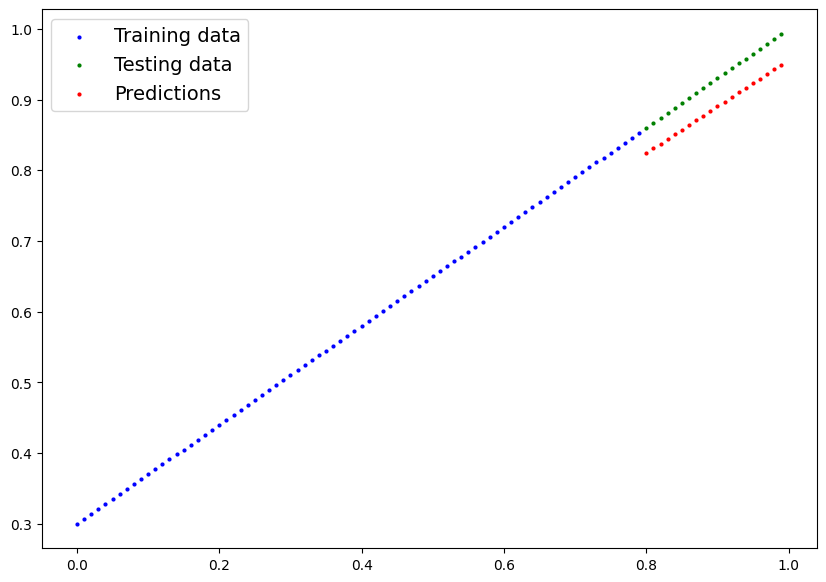

In [172]:
#Turn on evaluation mode
model_2.eval()

#make predictions (inference)
with torch.inference_mode():
  y_preds=model_2(X_test_regression)

#PLot data and predictions
# def plot_predictions(
#     train_data, train_labels, test_data, test_labels, predictions=None
# ):

#you have to
plot_predictions(train_data=X_train_regression.cpu(),
                 train_labels=y_train_regression.cpu(),
                 test_data=X_test_regression.cpu(),
                 test_labels=y_test_regression.cpu(),
                 predictions=y_preds.cpu())



## 6.The missing piece :non-linearity

"What patterns could you draw if you were given an infinite amount of a straight and non-straight line ? "

 Or in machine learning terms, an infinite(but really it is finite) of linear and non-linear functions ?



### 6.1Reacreting non-linear data(red and blue circles)

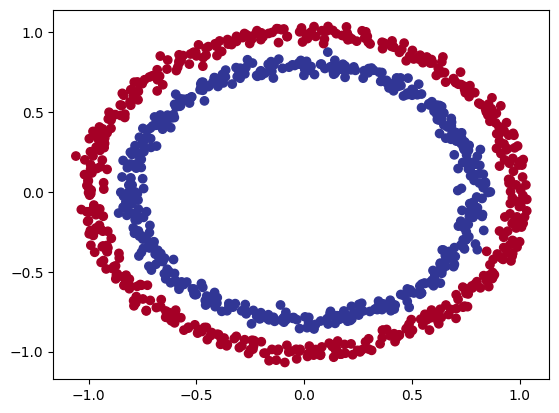

In [173]:
#make and plot data
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
n_samples=1000

X,y=make_circles(n_samples,
                 noise=0.03,
                 random_state=42)

plt.scatter(X[:,0],X[:,1],c=y,cmap=plt.cm.RdYlBu);

In [174]:
#Convert data to tensors and then to train and test splits
import torch
from sklearn.model_selection import train_test_split

#Turn data into tensors
X=torch.from_numpy(X).type(torch.float)
y=torch.from_numpy(y).type(torch.float)

#split into train and test sets
X_train,X_test,y_train,y_test=train_test_split(X,
                                               y,
                                               test_size=0.2,
                                               random_state=42)
X_train[:5],y_train[:5]



(tensor([[ 0.6579, -0.4651],
         [ 0.6319, -0.7347],
         [-1.0086, -0.1240],
         [-0.9666, -0.2256],
         [-0.1666,  0.7994]]),
 tensor([1., 0., 0., 0., 1.]))

### 6.2Building a model with ono-linearity
* Linear=straight linear
* Non-linear=non-straight lines

Artificial neural networks are a large combination of linear (straight) and non-straight(non-linear) functions whci are potentially able to find patterns in data

In [175]:
#Build a model with non-linear activation functions
from torch import nn
class CircleModelV2(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_1=nn.Linear(in_features=2,out_features=10)
    self.layer_2=nn.Linear(in_features=10,out_features=10)
    self.layer_3=nn.Linear(in_features=10,out_features=1)
    self.relu=nn.ReLU()

  def forward(self, x):
    return self.layer_3(
        self.relu(
            self.layer_2(
                self.relu(self.layer_1(x))
            )
        )
    )# this way of writing operations leverages speed ups where possible behind the scene

model_3=CircleModelV2().to(device)
model_3




CircleModelV2(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [176]:
#Setup loss and optimizer
loss_fn=nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_3.parameters(), lr=0.1)# Adam 比 SGD 更聰明地調整每個參數的 Learning Rate


### 6.3Training a model with non-linearity

In [177]:
#Random seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

#PUt all data on target device
#X_train,X_test,y_train,y_test
X_train,y_train=X_train.to(device),y_train.to(device)
X_test,y_test=X_test.to(device),y_test.to(device)

#Loop through data
epochs=1000

#Training Loop
for epoch in range(epochs):
  ###training
  model_3.train()

  #forward
  y_logits=model_3(X_train).squeeze(dim=1)#降一個維度 讓他跟y_train 一樣dim
  y_pred=torch.round(torch.sigmoid(y_logits)) #logits ->predixtion probabilities ->prediction labels

  #calculate the loss
  loss=loss_fn(y_logits,y_train) #BCEWtithLogitsLoss(takes in logits as first input)
  acc=accuracy_fn(y_true=y_train,
                  y_pred=y_pred)

  #optimizer to zero grad
  optimizer.zero_grad()

  #Backpropagation
  loss.backward()
  #gradient descent
  optimizer.step()

  model_3.eval()

  with torch.inference_mode():
    test_logits=model_3(X_test).squeeze()
    test_pred=torch.round(torch.sigmoid(test_logits))

    test_loss=loss_fn(test_logits,y_test)
    test_acc=accuracy_fn(y_true=y_test,
                         y_pred=test_pred)
  #print out what's this happenin

  if epoch % 100==0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.5f}")





Epoch: 0 | Loss: 0.69295, Acc: 50.00% | Test Loss: 0.69394, Test Acc: 50.00000
Epoch: 100 | Loss: 0.00168, Acc: 100.00% | Test Loss: 0.00744, Test Acc: 100.00000
Epoch: 200 | Loss: 0.00071, Acc: 100.00% | Test Loss: 0.00543, Test Acc: 100.00000
Epoch: 300 | Loss: 0.00041, Acc: 100.00% | Test Loss: 0.00493, Test Acc: 100.00000
Epoch: 400 | Loss: 0.00026, Acc: 100.00% | Test Loss: 0.00573, Test Acc: 100.00000
Epoch: 500 | Loss: 0.00018, Acc: 100.00% | Test Loss: 0.00516, Test Acc: 100.00000
Epoch: 600 | Loss: 0.00013, Acc: 100.00% | Test Loss: 0.00513, Test Acc: 100.00000
Epoch: 700 | Loss: 0.00010, Acc: 100.00% | Test Loss: 0.00534, Test Acc: 100.00000
Epoch: 800 | Loss: 0.00008, Acc: 100.00% | Test Loss: 0.00560, Test Acc: 100.00000
Epoch: 900 | Loss: 0.00007, Acc: 100.00% | Test Loss: 0.00577, Test Acc: 100.00000


### 6.4Evaluating a model trained with non-linear activation functions

In [178]:
#make predictions
model_3.eval()
with torch.inference_mode():
  y_preds=torch.round(torch.sigmoid(model_3(X_test))).squeeze()
y_preds[:10],y_test[:10]

(tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.], device='cuda:0'),
 tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.], device='cuda:0'))

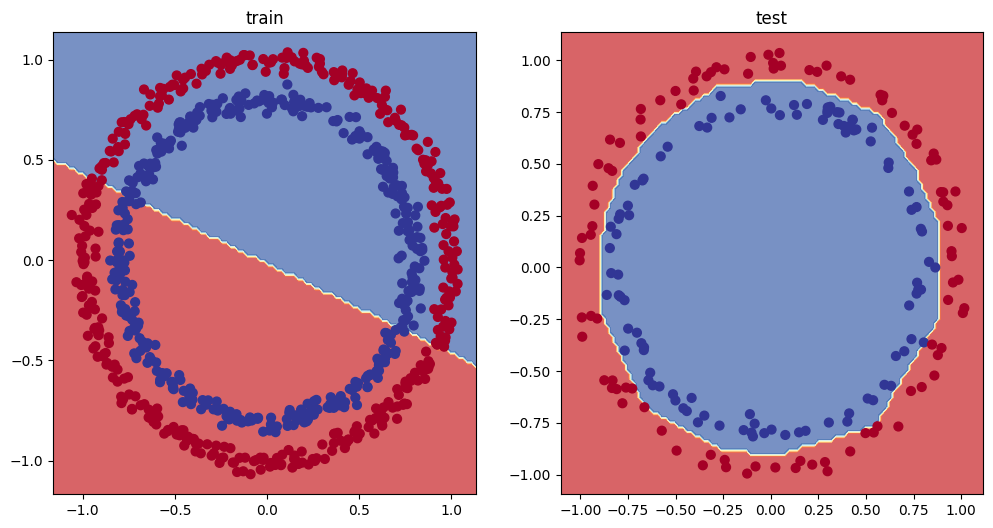

In [179]:
#plot decisionboundaries
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("train")
plot_decision_boundary(model_1,X_train,y_train)#model_1 no non-linearity
plt.subplot(1,2,2)
plt.title("test")
plot_decision_boundary(model_3,X_test,y_test)

## 7.Replicating non-linear activation functions

Rather than telling a neural network what to learn, we give it the tools to discover patterns in data, allowing it to figure out these patterns on its own.

These tools are linear and non-linear functions.

In [180]:
#create a tensor
A=torch.arange(-10,10,1,dtype=torch.float32)
A.dtype

torch.float32

In [181]:
A

tensor([-10.,  -9.,  -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.,   0.,   1.,
          2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.])

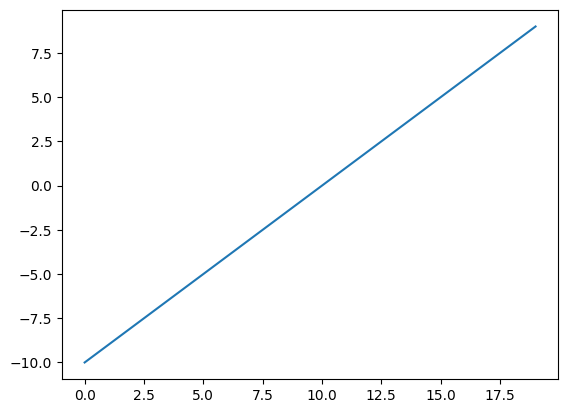

In [182]:
plt.plot(A);

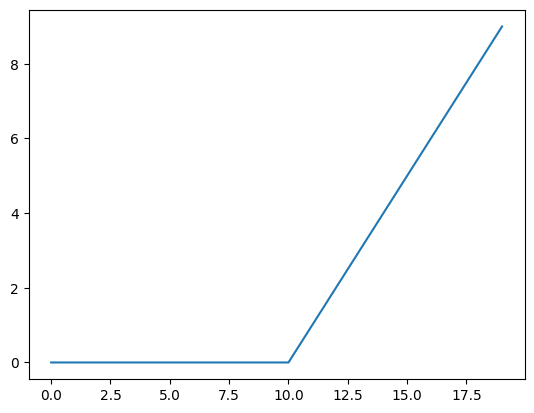

In [183]:
plt.plot(torch.relu(A))

In [184]:
def relu(x) ->torch.Tensor:
  return torch.maximum(torch.tensor(0),x)

relu(A)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 2., 3., 4., 5., 6., 7.,
        8., 9.])

In [185]:
#sigmoid

def sigmoid(x):
  return 1/(1+torch.exp(-x))

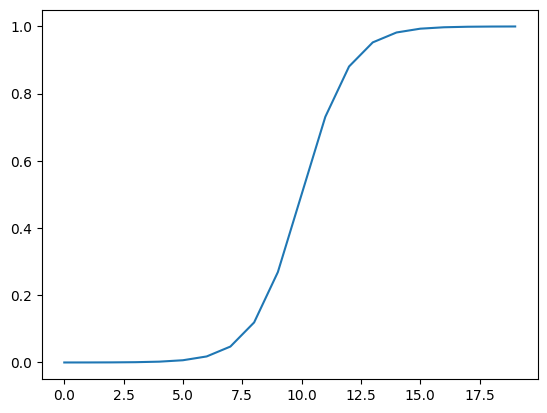

In [186]:
plt.plot(torch.sigmoid(A))

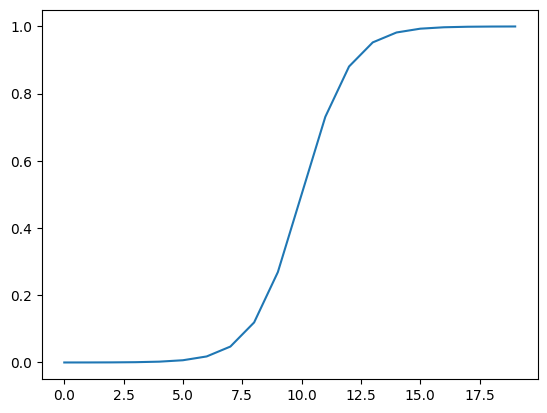

In [187]:
plt.plot(sigmoid(A))

## 8.Putting it all together with a multi-class classification problem

* Binary classfication =one thing or another (cat vs. dog,spam vs. not spam, fraud or not fraud)

* Multi-class classification=more than one thing or another (cat vs. dog vs.chicken)

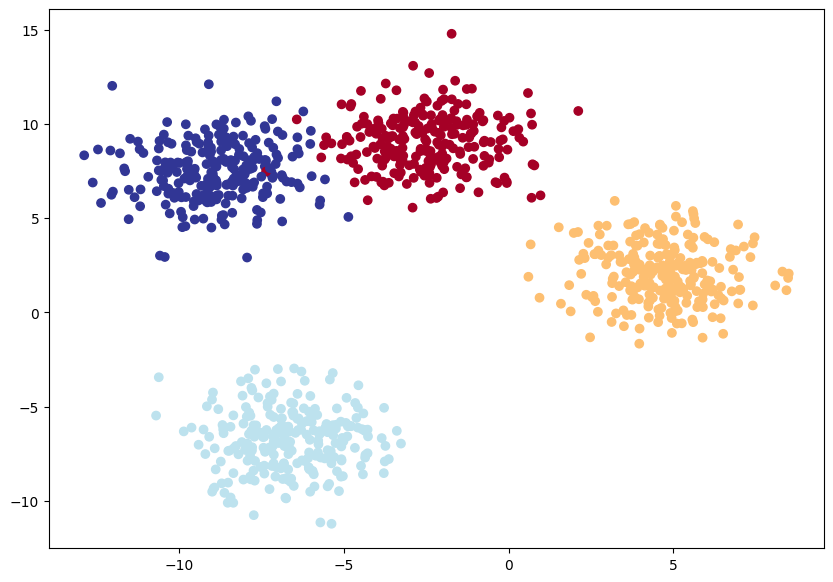

In [188]:
#Import dependencies
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs#https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html
from sklearn.model_selection import train_test_split

#Set the hyperparameters for data creation
NUM_CLASSES=4
NUM_FEATURES=2
RANDOM_SEED=42

#1. Create multi-class data
X_blob,y_blob=make_blobs(n_samples=1000,
                         n_features=NUM_FEATURES,
                         centers=NUM_CLASSES,
                         cluster_std=1.5,#give the classes a little shake up
                         random_state=RANDOM_SEED)

#2. Turn data into tensors
X_blob=torch.from_numpy(X_blob).type(torch.float)
y_blob=torch.from_numpy(y_blob).type(torch.LongTensor)

#3. Split into train and test sets
X_blob_train,X_blob_test,y_blob_train,y_blob_test=train_test_split(X_blob,
                                               y_blob,
                                               test_size=0.2,
                                               random_state=RANDOM_SEED)

#4. plot data (visualsize,visualsize,visualsize)
plt.figure(figsize=(10,7))
plt.scatter(X_blob[:,0],X_blob[:,1],c=y_blob,cmap=plt.cm.RdYlBu)

### 8.2Building amulti-class classification model in PyTorch

In [189]:
##Create device agnosirc ode
device="cuda" if torch.cuda.is_available() else "cpu"

print(device)

cuda


In [190]:
from torch import nn

# Build a multi-class classification model
class BlobModel(nn.Module):
    def __init__(self, input_features, output_features, hidden_units):
        """Initializes multi-class classification model.

        Args:
            input_features (int): Number of input features to the model
            output_features (int): Number of output features (number of output classes)
            hidden_units (int): Number of hidden units between layers, default 8

        Returns:

        Example:
        """
        super().__init__()

        self.linear_layer_stack = nn.Sequential(
            nn.Linear(in_features=input_features, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_features)
        )

    def forward(self, x):
        return self.linear_layer_stack(x)

#Create an instance of BolbModel and send it to the target device
model_4=BlobModel(input_features=2, output_features=4, hidden_units=8).to(device)
model_4



BlobModel(
  (linear_layer_stack): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=4, bias=True)
  )
)

### 8.3 Create a loss function and an optimizer for a multi-class classification model


In [191]:
#set optimizer and loss_fn

loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(params=model_4.parameters(),lr=0.1)

### 8.4 Getting prediction probabilites for a multi-calss Pytorch model

Inorder to evaluate and train and test out model,we need to convert our model's
outputs(logits) to prediction probabilities and then to prediction labels.

Logits (raw output of the model) ->Pred probs ->Pred Labels


In [192]:
#Let's get some raw outputs of our model (LOGITS)
model_4.eval()
with torch.inference_mode():
    y_preds=model_4(X_blob_test.to(device))

y_preds[:10]

tensor([[-0.7646, -0.7412, -1.5777, -1.1376],
        [-0.0973, -0.9431, -0.5963, -0.1371],
        [ 0.2528, -0.2379,  0.1882, -0.0066],
        [-0.4134, -0.5204, -0.9303, -0.6963],
        [-0.3118, -1.3736, -1.1991, -0.3834],
        [-0.1497, -1.0617, -0.7107, -0.1645],
        [ 0.1539, -0.2887,  0.1520, -0.0109],
        [-0.2154, -1.1795, -0.9300, -0.2745],
        [ 0.2443, -0.2472,  0.1649,  0.0061],
        [-0.2329, -1.2120, -0.9849, -0.3004]], device='cuda:0')

In [193]:
y_blob_test[:10]

tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0])

In [194]:
#Convert our model's logit outputs to prediction probabilites
y_pred_probs=torch.softmax(y_preds,dim=1)
y_pred_probs[:10]


tensor([[0.3169, 0.3244, 0.1405, 0.2182],
        [0.3336, 0.1432, 0.2026, 0.3206],
        [0.3011, 0.1843, 0.2823, 0.2323],
        [0.3078, 0.2766, 0.1836, 0.2320],
        [0.3719, 0.1286, 0.1532, 0.3463],
        [0.3381, 0.1358, 0.1929, 0.3331],
        [0.2867, 0.1841, 0.2861, 0.2431],
        [0.3554, 0.1355, 0.1740, 0.3351],
        [0.3009, 0.1841, 0.2779, 0.2371],
        [0.3595, 0.1350, 0.1695, 0.3360]], device='cuda:0')

In [195]:
#test if the softmax works
torch.sum(y_pred_probs[0])

tensor(1., device='cuda:0')

In [196]:
#convert our model's prediction probabilities to prediction labels
#torch.argmax dim 0 follow cols up to down dim1 follow rows left to right find the biggest index
y_preds=torch.argmax(y_pred_probs,dim=1)
y_preds[:]


tensor([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 3, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
        1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 1, 0, 1, 0, 0, 0,
        0, 0, 0, 0, 3, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        1, 0, 0, 0, 0, 1, 0, 1], device='cuda:0')

### 8.5training loop

In [197]:
# Fit the multi-class model to the data
torch.manual_seed(42)
torch.cuda.manual_seed(42)

#set epoch
epoch=100

#put data to target device
X_blob_train,y_blob_train=X_blob_train.to(device),y_blob_train.to(device)
X_blob_test,y_blob_test=X_blob_test.to(device),y_blob_test.to(device)

#training loop
for epoch in range(epoch):
  #default
  model_4.train()

  #forward pass
  y_logits=model_4(X_blob_train)
  y_preds=torch.softmax(y_logits,dim=1).argmax(dim=1)

  loss=loss_fn(y_logits,y_blob_train)
  acc=accuracy_fn(y_true=y_blob_train,
                  y_pred=y_preds)

  #optimizer zero grad
  optimizer.zero_grad()

  #loss backward
  loss.backward()

  #optimizer step
  optimizer.step()

  model_4.eval()
  with torch.inference_mode():
    test_logits=model_4(X_blob_test)
    test_preds=torch.softmax(test_logits,dim=1).argmax(dim=1)

    test_loss=loss_fn(test_logits,y_blob_test)
    test_acc=accuracy_fn(y_true=y_blob_test,
                    y_pred=test_preds)

  if epoch % 10 ==0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")


Epoch: 0 | Loss: 1.15883, Acc: 40.38% | Test Loss: 0.81667, Test Acc: 68.50%
Epoch: 10 | Loss: 0.03970, Acc: 98.75% | Test Loss: 0.01952, Test Acc: 99.50%
Epoch: 20 | Loss: 0.03161, Acc: 99.25% | Test Loss: 0.00442, Test Acc: 100.00%
Epoch: 30 | Loss: 0.02219, Acc: 99.12% | Test Loss: 0.00606, Test Acc: 99.50%
Epoch: 40 | Loss: 0.01999, Acc: 99.50% | Test Loss: 0.00690, Test Acc: 99.50%
Epoch: 50 | Loss: 0.01866, Acc: 99.50% | Test Loss: 0.00842, Test Acc: 99.50%
Epoch: 60 | Loss: 0.01779, Acc: 99.50% | Test Loss: 0.00693, Test Acc: 100.00%
Epoch: 70 | Loss: 0.01723, Acc: 99.38% | Test Loss: 0.00528, Test Acc: 100.00%
Epoch: 80 | Loss: 0.01661, Acc: 99.38% | Test Loss: 0.00442, Test Acc: 100.00%
Epoch: 90 | Loss: 0.01617, Acc: 99.38% | Test Loss: 0.00472, Test Acc: 100.00%


### 8.6 Making and evaluting predictions with a PyTorch multi-class model

In [198]:
model_4.eval()
with torch.inference_mode():
  y_logits=model_4(X_blob_test)

#View the firsst 1 predictions
y_logits[:10]


tensor([[-18.3237,  21.5063, -52.0447, -39.1625],
        [  0.2761, -18.8128, -25.6507,   6.7659],
        [-44.4127, -50.4673,  38.5688,  -8.0357],
        [-22.6778,  24.1571, -40.0097, -36.0014],
        [  9.6104,  -8.1985, -36.7782, -11.9078],
        [ -0.6148, -22.5725, -30.3283,   9.1413],
        [-43.4761, -49.2270,  37.6196,  -7.8760],
        [  8.3179, -12.4781, -29.8828,  -4.9878],
        [-49.2035, -56.0150,  42.8070,  -8.9079],
        [  8.6234, -10.5103, -31.8065,  -7.5910]], device='cuda:0')

In [199]:
#Go from logits ->Prediction probabilites
y_pred_probs=torch.softmax(y_logits,dim=1)
y_pred_probs[:10]
# torch.sum(y_pred_probs[0])

tensor([[5.0356e-18, 1.0000e+00, 1.1408e-32, 4.4861e-27],
        [1.5166e-03, 7.7740e-12, 8.3370e-15, 9.9848e-01],
        [9.1539e-37, 2.1484e-39, 1.0000e+00, 5.7534e-21],
        [4.5693e-21, 1.0000e+00, 1.3574e-28, 7.4724e-27],
        [1.0000e+00, 1.8437e-08, 7.1394e-21, 4.5159e-10],
        [5.7937e-05, 1.6861e-14, 7.2206e-18, 9.9994e-01],
        [6.0335e-36, 1.9187e-38, 1.0000e+00, 1.7439e-20],
        [1.0000e+00, 9.2988e-10, 2.5682e-17, 1.6649e-06],
        [1.0974e-40, 1.2051e-43, 1.0000e+00, 3.4716e-23],
        [1.0000e+00, 4.9017e-09, 2.7639e-18, 9.0821e-08]], device='cuda:0')

In [200]:
#Go from pred probs to pred labels
y_preds=torch.argmax(y_pred_probs,dim=1)
y_preds[:10]

tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0], device='cuda:0')

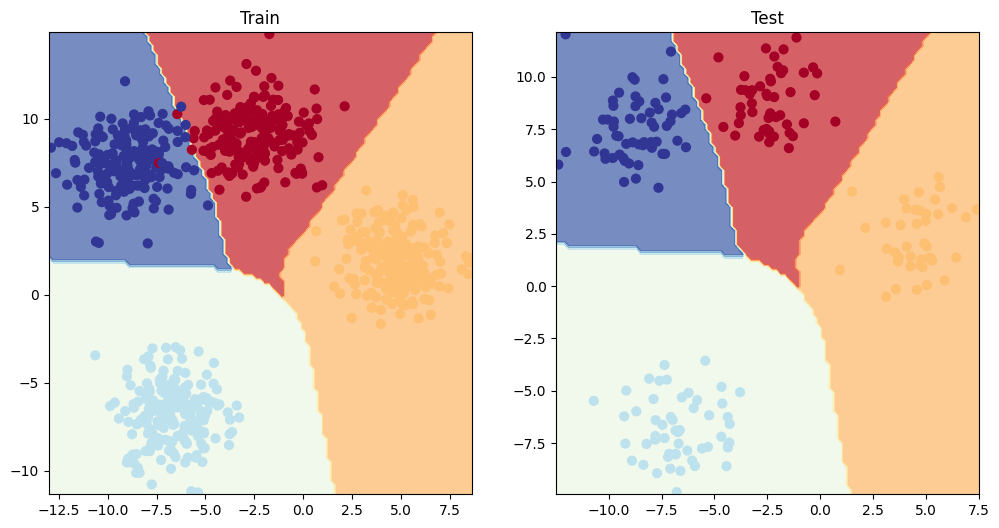

In [201]:
from helper_functions import plot_predictions, plot_decision_boundary

plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_4,X_blob_train,y_blob_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_4,X_blob_test,y_blob_test)


## 9. A few more classification matrics...(to evalute out classification matrics)

* Accuracy -out of 100 samples,how many does our model get rigtht
* Precision
* recall

In [202]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 22.3 MB/s eta 0:00:00


In [207]:
from torchmetrics import Accuracy

#Setup metric

torchmetric_accuracy = Accuracy(

    task="multiclass",

    num_classes=4

).to(device)
torchmetric_accuracy(y_preds,y_blob_test)

tensor(1., device='cuda:0')

In [208]:
torchmetric_accuracy.device

device(type='cuda', index=0)